# Human vs AI Writing Pattern Analyzer — NLP + ML

This notebook builds a RAM-friendly baseline for **human-like vs AI-like writing classification**.

### Main idea
Use paired Wikipedia data: each topic has a human Wikipedia introduction and an AI-generated introduction. We split by topic ID so the two versions of the same topic cannot leak across train/test.

Pipeline:
**paired data → preprocessing → word/character TF-IDF + stylometric NLP features → Logistic Regression → evaluation → single-text analyzer**

> The output is a probability/pattern classification, not proof of authorship.

## 0. Install dependencies

In [1]:
!pip -q install -U datasets scikit-learn scipy pandas numpy matplotlib seaborn joblib textstat

  You can safely remove it manually.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_auc_score
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
print("Libraries loaded.")

c:\Users\new user farhat\NLP-Project-Ai-human-written-\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries loaded.


## 1. Configuration
Start with 5,000 paired topics = about 10,000 texts. Increase only after the complete pipeline works.

In [4]:
N_PAIRS = 5000
WORD_MAX_FEATURES = 20000
CHAR_MAX_FEATURES = 15000
print(f"Using up to {N_PAIRS:,} paired topics = about {2*N_PAIRS:,} texts.")

Using up to 5,000 paired topics = about 10,000 texts.


## 2. Load GPT-Wiki-Intro with streaming
Streaming prevents the full 150k-row dataset from being loaded into RAM.

In [5]:
DATASET_NAME = "aadityaubhat/GPT-wiki-intro"

stream = load_dataset(DATASET_NAME, split="train", streaming=True)
stream = stream.shuffle(seed=RANDOM_STATE, buffer_size=10000)

rows = []
for row in stream:
    rows.append({
        "id": row["id"],
        "title": row["title"],
        "wiki_intro": row["wiki_intro"],
        "generated_intro": row["generated_intro"]
    })
    if len(rows) >= N_PAIRS:
        break

raw = pd.DataFrame(rows)
print("Paired topics:", len(raw))
print(raw.columns.tolist())
display(raw.head(2))

Paired topics: 5000
['id', 'title', 'wiki_intro', 'generated_intro']


,id,title,wiki_intro,generated_intro
0,2733525,Cervical cerclage,"Cervical cerclage, also known as a cervical st...","Cervical cerclage, also known as a cervical co..."
1,20438122,Australian Jews,"Australian Jews, or Jewish Australians, are J...","Australian Jews, or Jewish Australians, are J..."


## 3. Create Human/AI classification data
`0 = Human/Wikipedia`, `1 = AI/generated`.

In [6]:
human = raw[["id", "title", "wiki_intro"]].rename(columns={"wiki_intro": "text"}).copy()
human["label"] = 0

ai = raw[["id", "title", "generated_intro"]].rename(columns={"generated_intro": "text"}).copy()
ai["label"] = 1

data = pd.concat([human, ai], ignore_index=True)
data["text"] = data["text"].astype(str).str.strip()
data = data[data["text"].str.len() >= 100].drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Shape:", data.shape)
print(data["label"].value_counts().sort_index())
display(data[["title", "label", "text"]].sample(4, random_state=RANDOM_STATE))

Shape: (9991, 4)
label
0    5000
1    4991
Name: count, dtype: int64


,title,label,text
4023,Israel Ori,0,Israel Ori (1658–1711) was a prominent figure...
7346,Margaret Calvert,1,Margaret Vivienne Calvert (born 1936) is a Br...
487,SS Nubia (1854),0,"SS Nubia was a passenger steamer, built by Joh..."
39,Odipolama,0,Odipolama is a 2009 Indian Tamil-language rom...


## 4. Leakage-safe train/test split
Split by `id`, not by individual text rows. This keeps the human and AI versions of each topic together.

In [7]:
unique_ids = data["id"].drop_duplicates()

train_ids, test_ids = train_test_split(
    unique_ids, test_size=0.20, random_state=RANDOM_STATE
)

train_df = data[data["id"].isin(train_ids)].reset_index(drop=True)
test_df = data[data["id"].isin(test_ids)].reset_index(drop=True)

assert set(train_df["id"]).isdisjoint(set(test_df["id"]))

print("Train:", train_df.shape)
print("Test :", test_df.shape)
print("\nTrain labels:\n", train_df["label"].value_counts().sort_index())
print("\nTest labels:\n", test_df["label"].value_counts().sort_index())
print("\nLeakage check passed.")

Train: (7992, 4)
Test : (1999, 4)

Train labels:
 label
0    4000
1    3992
Name: count, dtype: int64

Test labels:
 label
0    1000
1     999
Name: count, dtype: int64

Leakage check passed.


## 5. NLP/stylometric feature extraction
Features: sentence length, sentence variation, vocabulary diversity, word length, punctuation, repetition, pronouns, paragraph variation, long words, and contractions.

In [8]:
WORD_RE = re.compile(r"\b[a-zA-Z]+(?:'[a-zA-Z]+)?\b")
SENT_RE = re.compile(r"(?<=[.!?])\s+")
PARA_RE = re.compile(r"\n\s*\n+")
PRONOUNS = {"i","me","my","mine","we","us","our","ours","you","your","yours","he","him","his","she","her","hers","they","them","their","theirs","it","its"}
CONTRACTIONS = re.compile(
    r"\b(?:can't|won't|isn't|aren't|wasn't|weren't|don't|doesn't|didn't|i'm|i've|i'll|i'd|we're|we've|we'll|they're|they've|you're|you've|it's|that's|there's|what's)\b",
    re.I
)

FEATURE_NAMES = [
    "avg_sentence_length", "sentence_length_std", "vocabulary_diversity",
    "avg_word_length", "punctuation_ratio", "repetition_ratio",
    "pronoun_ratio", "paragraph_length_std", "max_sentence_length",
    "min_sentence_length", "long_word_ratio", "question_exclamation_ratio",
    "contraction_ratio"
]

def extract_style_features(text):
    text = str(text)
    words = WORD_RE.findall(text.lower())
    if not words:
        return np.zeros(len(FEATURE_NAMES), dtype=np.float32)

    sentences = [s.strip() for s in SENT_RE.split(text) if s.strip()]
    sentence_lengths = [len(WORD_RE.findall(s)) for s in sentences]
    sentence_lengths = [x for x in sentence_lengths if x > 0] or [len(words)]

    paragraphs = [p.strip() for p in PARA_RE.split(text) if p.strip()]
    paragraph_lengths = [len(WORD_RE.findall(p)) for p in paragraphs]

    counts = pd.Series(words).value_counts()
    repeated_word_count = counts[counts > 1].sum() if len(counts) else 0

    total_words = len(words)
    punctuation_count = len(re.findall(r"[,.;:!?-]", text))
    pronoun_count = sum(w in PRONOUNS for w in words)
    long_word_count = sum(len(w) >= 8 for w in words)
    q_e_count = len(re.findall(r"[!?]", text))
    contraction_count = len(CONTRACTIONS.findall(text))

    return np.asarray([
        np.mean(sentence_lengths),
        np.std(sentence_lengths),
        len(set(words)) / total_words,
        np.mean([len(w) for w in words]),
        punctuation_count / total_words,
        repeated_word_count / total_words,
        pronoun_count / total_words,
        np.std(paragraph_lengths) if len(paragraph_lengths) > 1 else 0.0,
        max(sentence_lengths),
        min(sentence_lengths),
        long_word_count / total_words,
        q_e_count / total_words,
        contraction_count / total_words
    ], dtype=np.float32)

def make_style_matrix(texts):
    return np.vstack([extract_style_features(t) for t in texts])

print("Feature count:", len(FEATURE_NAMES))
print(FEATURE_NAMES)

Feature count: 13
['avg_sentence_length', 'sentence_length_std', 'vocabulary_diversity', 'avg_word_length', 'punctuation_ratio', 'repetition_ratio', 'pronoun_ratio', 'paragraph_length_std', 'max_sentence_length', 'min_sentence_length', 'long_word_ratio', 'question_exclamation_ratio', 'contraction_ratio']


## 6. Extract and scale stylometric features

In [9]:
X_train_style_raw = make_style_matrix(train_df["text"].tolist())
X_test_style_raw = make_style_matrix(test_df["text"].tolist())

scaler = StandardScaler()
X_train_style = scaler.fit_transform(X_train_style_raw)
X_test_style = scaler.transform(X_test_style_raw)

print("Train style matrix:", X_train_style.shape)
print("Test style matrix :", X_test_style.shape)
display(pd.DataFrame(X_train_style_raw, columns=FEATURE_NAMES).describe().T)

Train style matrix: (7992, 13)
Test style matrix : (1999, 13)


,count,mean,std,min,25%,50%,75%,max
avg_sentence_length,7992.0,19.218441,8.550116,2.272727,15.156883,18.000000,21.428572,274.000000
sentence_length_std,7992.0,7.962859,6.086143,0.000000,5.013870,6.888033,9.284860,114.351311
vocabulary_diversity,7992.0,0.589853,0.083772,0.179167,0.540000,0.588608,0.638554,0.964286
avg_word_length,7992.0,4.908427,0.384424,3.514286,4.660098,4.872093,5.107419,9.519737
punctuation_ratio,7992.0,0.136844,0.042399,0.005952,0.111111,0.132075,0.155405,1.172840
repetition_ratio,7992.0,0.575570,0.105794,0.071429,0.512883,0.571429,0.633144,1.000000
pronoun_ratio,7992.0,0.035678,0.023881,0.000000,0.016321,0.032967,0.052356,0.145631
paragraph_length_std,7992.0,7.420906,10.835068,0.000000,0.000000,0.000000,13.274153,104.000000
max_sentence_length,7992.0,33.476601,16.842760,6.000000,24.000000,30.000000,38.000000,274.000000
min_sentence_length,7992.0,8.735110,7.793241,1.000000,5.000000,8.000000,11.000000,274.000000


## 7. Word-level TF-IDF

In [10]:
word_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    max_features=WORD_MAX_FEATURES,
    sublinear_tf=True
)

X_train_word = word_vectorizer.fit_transform(train_df["text"])
X_test_word = word_vectorizer.transform(test_df["text"])

print("Word TF-IDF:", X_train_word.shape)

Word TF-IDF: (7992, 20000)


## 8. Character-level TF-IDF
Character n-grams add style/spelling/punctuation signals and reduce dependence on exact words.

In [11]:
char_vectorizer = TfidfVectorizer(
    analyzer="char",
    lowercase=True,
    ngram_range=(3, 5),
    min_df=3,
    max_features=CHAR_MAX_FEATURES,
    sublinear_tf=True
)

X_train_char = char_vectorizer.fit_transform(train_df["text"])
X_test_char = char_vectorizer.transform(test_df["text"])

print("Character TF-IDF:", X_train_char.shape)

Character TF-IDF: (7992, 15000)


## 9. Build feature sets
We compare TF-IDF only, stylometry only, and the combined model.

In [12]:
X_train_tfidf = hstack([X_train_word, X_train_char], format="csr")
X_test_tfidf = hstack([X_test_word, X_test_char], format="csr")

X_train_style_sparse = csr_matrix(X_train_style)
X_test_style_sparse = csr_matrix(X_test_style)

X_train_combined = hstack([X_train_tfidf, X_train_style_sparse], format="csr")
X_test_combined = hstack([X_test_tfidf, X_test_style_sparse], format="csr")

y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("TF-IDF:", X_train_tfidf.shape)
print("Style :", X_train_style_sparse.shape)
print("Combined:", X_train_combined.shape)

TF-IDF: (7992, 35000)
Style : (7992, 13)
Combined: (7992, 35013)


## 10. Evaluation helper

In [13]:
def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    scores = {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob)
    }

    print(f"\n===== {name} =====")
    print(pd.Series(scores))
    print("\nClassification report:")
    print(classification_report(
        y_test, pred, target_names=["Human", "AI"], zero_division=0
    ))
    return model, scores, pred, prob

results = []

In [14]:
tfidf_model, score_tfidf, pred_tfidf, prob_tfidf = evaluate_model(
    LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced"),
    X_train_tfidf, X_test_tfidf, y_train, y_test, "TF-IDF only"
)
results.append(score_tfidf)


===== TF-IDF only =====
model        TF-IDF only
accuracy        0.945973
precision       0.961658
recall          0.928929
f1               0.94501
roc_auc         0.990968
dtype: object

Classification report:
              precision    recall  f1-score   support

       Human       0.93      0.96      0.95      1000
          AI       0.96      0.93      0.95       999

    accuracy                           0.95      1999
   macro avg       0.95      0.95      0.95      1999
weighted avg       0.95      0.95      0.95      1999



In [15]:
style_model, score_style, pred_style, prob_style = evaluate_model(
    LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced"),
    X_train_style_sparse, X_test_style_sparse, y_train, y_test, "Stylometric features only"
)
results.append(score_style)


===== Stylometric features only =====
model        Stylometric features only
accuracy                      0.958979
precision                     0.976116
recall                        0.940941
f1                            0.958206
roc_auc                       0.982961
dtype: object

Classification report:
              precision    recall  f1-score   support

       Human       0.94      0.98      0.96      1000
          AI       0.98      0.94      0.96       999

    accuracy                           0.96      1999
   macro avg       0.96      0.96      0.96      1999
weighted avg       0.96      0.96      0.96      1999



In [16]:
combined_model, score_combined, pred_combined, prob_combined = evaluate_model(
    LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced"),
    X_train_combined, X_test_combined, y_train, y_test, "TF-IDF + stylometric features"
)
results.append(score_combined)


===== TF-IDF + stylometric features =====
model        TF-IDF + stylometric features
accuracy                          0.974987
precision                         0.982706
recall                            0.966967
f1                                0.974773
roc_auc                            0.98879
dtype: object

Classification report:
              precision    recall  f1-score   support

       Human       0.97      0.98      0.98      1000
          AI       0.98      0.97      0.97       999

    accuracy                           0.97      1999
   macro avg       0.98      0.97      0.97      1999
weighted avg       0.98      0.97      0.97      1999



## 11. Compare models

,model,accuracy,precision,recall,f1,roc_auc
2,TF-IDF + stylometric features,0.974987,0.982706,0.966967,0.974773,0.988790
1,Stylometric features only,0.958979,0.976116,0.940941,0.958206,0.982961
0,TF-IDF only,0.945973,0.961658,0.928929,0.945010,0.990968


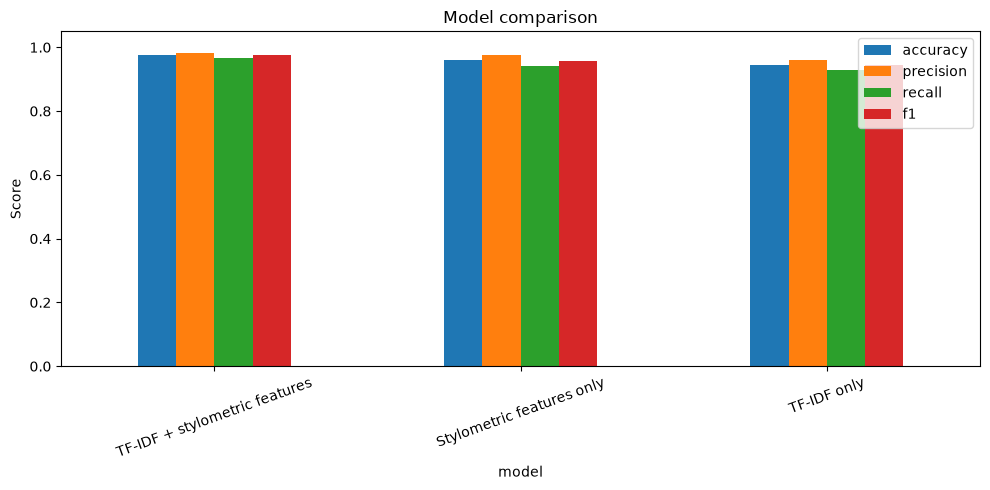

In [17]:
results_df = pd.DataFrame(results).sort_values("f1", ascending=False)
display(results_df)

ax = results_df.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(10, 5)
)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 12. Confusion matrix

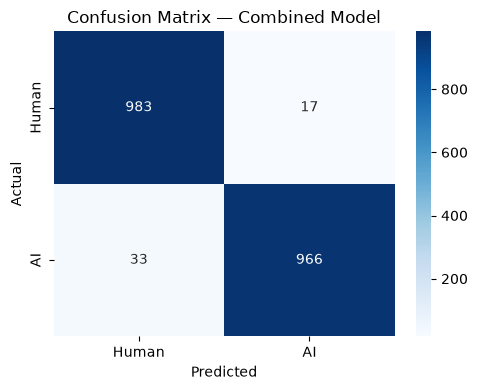

In [18]:
cm = confusion_matrix(y_test, pred_combined)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Human", "AI"],
    yticklabels=["Human", "AI"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Combined Model")
plt.tight_layout()
plt.show()

## 13. Inspect style differences

In [19]:
style_train_df = pd.DataFrame(X_train_style_raw, columns=FEATURE_NAMES)
style_train_df["label"] = y_train

means = style_train_df.groupby("label")[FEATURE_NAMES].mean().T
means.columns = ["Human", "AI"]
display(means)

std_diff = (means["AI"] - means["Human"]) / (style_train_df[FEATURE_NAMES].std() + 1e-8)
feature_effects = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "human_mean": means["Human"].values,
    "ai_mean": means["AI"].values,
    "standardized_difference": std_diff.values
}).sort_values("standardized_difference", key=np.abs, ascending=False)

display(feature_effects)

,Human,AI
avg_sentence_length,21.940767,16.490662
sentence_length_std,10.328427,5.592549
vocabulary_diversity,0.587213,0.592498
avg_word_length,4.970153,4.846576
punctuation_ratio,0.135081,0.138610
repetition_ratio,0.565065,0.586095
pronoun_ratio,0.033492,0.037867
paragraph_length_std,0.558143,14.297423
max_sentence_length,41.042500,25.895540
min_sentence_length,8.707500,8.762775


,feature,human_mean,ai_mean,standardized_difference
7,paragraph_length_std,0.558143,14.297423,1.268038
8,max_sentence_length,41.042500,25.895540,-0.899316
1,sentence_length_std,10.328427,5.592549,-0.778141
0,avg_sentence_length,21.940767,16.490662,-0.637431
3,avg_word_length,4.970153,4.846576,-0.321461
5,repetition_ratio,0.565065,0.586095,0.198783
6,pronoun_ratio,0.033492,0.037867,0.183185
10,long_word_ratio,0.186991,0.177552,-0.159513
4,punctuation_ratio,0.135081,0.138610,0.083246
11,question_exclamation_ratio,0.000233,0.000134,-0.066664


## 14. Inspect top TF-IDF features

In [20]:
feature_names = np.concatenate([
    word_vectorizer.get_feature_names_out(),
    char_vectorizer.get_feature_names_out()
])

coef = tfidf_model.coef_[0]
top_ai_idx = np.argsort(coef)[-25:][::-1]
top_human_idx = np.argsort(coef)[:25]

print("Top features associated with AI class:")
display(pd.DataFrame({
    "feature": feature_names[top_ai_idx],
    "coefficient": coef[top_ai_idx]
}))

print("Top features associated with Human class:")
display(pd.DataFrame({
    "feature": feature_names[top_human_idx],
    "coefficient": coef[top_human_idx]
}))

Top features associated with AI class:


,feature,coefficient
0,. the,2.318518
1,born in,2.176903
2,. th,2.137138
3,. t,2.012897
4,has,1.865759
5,was born,1.595852
6,is,1.556121
7,died,1.498726
8,including,1.437701
9,has been,1.383753


Top features associated with Human class:


,feature,coefficient
0,this,-2.068861
1,of the,-1.806410
2,life,-1.682555
3,not,-1.670118
4,at,-1.648892
5,later,-1.623750
6,and in,-1.544429
7,history,-1.530562
8,early life,-1.529288
9,had,-1.523482


## 15. Single-text analyzer

In [21]:
def analyze_text(text):
    text = str(text).strip()
    if len(text) < 50:
        raise ValueError("Please provide a longer text (at least ~50 characters).")

    word_x = word_vectorizer.transform([text])
    char_x = char_vectorizer.transform([text])

    style_raw = np.array([extract_style_features(text)])
    style_scaled = scaler.transform(style_raw)

    combined_x = hstack([
        word_x,
        char_x,
        csr_matrix(style_scaled)
    ], format="csr")

    ai_probability = float(combined_model.predict_proba(combined_x)[0, 1])
    prediction = "AI-like" if ai_probability >= 0.5 else "Human-like"

    return {
        "prediction": prediction,
        "ai_probability": ai_probability,
        "human_probability": 1 - ai_probability,
        "style_features": pd.Series(style_raw[0], index=FEATURE_NAMES)
    }

# Test with one held-out example first:
sample_text = test_df.iloc[0]["text"]
result = analyze_text(sample_text)

print("Prediction:", result["prediction"])
print(f"AI-like probability: {result['ai_probability']:.2%}")
print(f"Human-like probability: {result['human_probability']:.2%}")
display(result["style_features"].to_frame("value"))

Prediction: Human-like
AI-like probability: 13.48%
Human-like probability: 86.52%


,value
avg_sentence_length,16.909090
sentence_length_std,5.212826
vocabulary_diversity,0.505376
avg_word_length,4.634408
punctuation_ratio,0.118280
repetition_ratio,0.623656
pronoun_ratio,0.005376
paragraph_length_std,0.000000
max_sentence_length,24.000000
min_sentence_length,9.000000


## 16. Test your own text

In [27]:
my_text = """Last Sunday, I decided to clean my study table because I could barely find anything on it anymore. There were notebooks everywhere, a couple of empty coffee cups, some old receipts, and a charger that I was sure I had been looking for for the last two weeks. I kept telling myself that it would only take ten minutes, but of course it took much longer.
While cleaning, I found an old notebook from my first year of college. I almost threw it away, but then I started going through the pages. Some of the notes were surprisingly neat, although others were basically impossible to understand. I had written down programming concepts, random ideas for projects, and even a few plans about things I wanted to learn. Looking at it now was a little funny because I had completely forgotten about most of those plans.
One thing that caught my attention was a page where I had written that I wanted to become better at programming and work on projects that were actually useful. I guess that part hasn't changed much. The tools I use now are different, and I understand many things that seemed confusing back then, but the basic goal is still there.
Cleaning the table didn't really change my life, obviously. Still, finding that notebook
"""
if "Paste your test text here." in my_text:
    print("Replace my_text with your own text and run this cell.")
else:
    result = analyze_text(my_text)
    print("Prediction:", result["prediction"])
    print(f"AI-like probability: {result['ai_probability']:.2%}")
    print(f"Human-like probability: {result['human_probability']:.2%}")
    display(result["style_features"].to_frame("value"))

Prediction: Human-like
AI-like probability: 2.07%
Human-like probability: 97.93%


,value
avg_sentence_length,16.769230
sentence_length_std,7.617327
vocabulary_diversity,0.619266
avg_word_length,4.527523
punctuation_ratio,0.119266
repetition_ratio,0.550459
pronoun_ratio,0.114679
paragraph_length_std,0.000000
max_sentence_length,30.000000
min_sentence_length,4.000000


## 17. Compare two texts from the same topic

In [28]:
def compare_texts(human_text, ai_text):
    human_result = analyze_text(human_text)
    ai_result = analyze_text(ai_text)

    print("Human text:", human_result["prediction"],
          f"({human_result['ai_probability']:.2%} AI-like)")
    print("AI text   :", ai_result["prediction"],
          f"({ai_result['ai_probability']:.2%} AI-like)")

    comparison = pd.DataFrame({
        "Feature": FEATURE_NAMES,
        "Human text": human_result["style_features"].values,
        "AI text": ai_result["style_features"].values
    })
    display(comparison)

# Example:
# compare_texts(human_version, ai_version)

## 18. Save the trained pipeline

In [29]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump(
    {
        "model": combined_model,
        "word_vectorizer": word_vectorizer,
        "char_vectorizer": char_vectorizer,
        "scaler": scaler,
        "feature_names": FEATURE_NAMES
    },
    "artifacts/ai_text_detector_pipeline.joblib"
)

print("Saved: artifacts/ai_text_detector_pipeline.joblib")

Saved: artifacts/ai_text_detector_pipeline.joblib


# 19. Final evaluation plan

Do not report only one random accuracy.

For your final project, evaluate:

1. **Paired Wikipedia test** — the held-out topics from this dataset.
2. **Unseen human Wikipedia** — articles not used for training.
3. **Unseen AI generator** — AI text generated by a model not represented in training.
4. **Different domain** — essays/news/blogs.

Report:

| Test set | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| Paired Wikipedia | ... | ... | ... | ... |
| Unseen Wikipedia | ... | ... | ... | ... |
| Unseen AI generator | ... | ... | ... | ... |
| Different domain | ... | ... | ... | ... |

A drop in cross-domain performance is useful information: it shows the limitations of AI-text detection rather than hiding them.

**Important:** call the output "AI-like/human-like classification" or "writing-pattern classification", not definitive proof of authorship.